# NHIỆM VỤ 2: TRÍCH CHỌN ĐẶC TRƯNG & VECTOR HÓA DỮ LIỆU
---
**Luồng thực hiện:**
1. Nạp và khảo sát 2 bộ dữ liệu: TikTok ($1.307$ mẫu) và Facebook ($2.087$ mẫu).
2. Phân chia Train ($80\%$) và Test ($20\%$) phân tầng trước khi vector hóa (Anti Data Leakage).
3. Chuyển đổi văn bản thành ma trận đặc trưng: **TF-IDF** và **Bag-of-Words (BoW)** kết hợp n-gram ($1-2\text{ gram}$).
4. Phân tích không gian từ vựng và đối sánh đặc trưng giữa 2 nền tảng.
5. Trực quan hóa phân bố nhãn và đặc trưng tiêu biểu.
6. Đóng gói ma trận bàn giao cho các nhánh mô hình học máy (Naive Bayes, SVM).

In [1]:
# 1. KHAI BÁO THƯ VIỆN & CẤU HÌNH
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

DATA_DIR = 'Data' if os.path.exists('Data') else os.path.join('..', 'Data')
print(f'Thư mục dữ liệu: {os.path.abspath(DATA_DIR)}')

Thư mục dữ liệu: C:\Nam 4 ki 1\Phan tich va khai pha du lieu van ban\BTL\Bai_1\Data


### Bước 1: Nạp và khảo sát dữ liệu 2 nguồn
- **TikTok**: $1.307$ mẫu (`Data/final_labeled_clean.xlsx`)
- **Facebook**: $2.087$ mẫu (`Data/final_labeled_clean_v3.xlsx`)

In [2]:
# 2. NẠP DỮ LIỆU ĐÃ LÀM SẠCH
path_tt = os.path.join(DATA_DIR, 'final_labeled_clean.xlsx')
path_fb = os.path.join(DATA_DIR, 'final_labeled_clean_v3.xlsx')

df_tt = pd.read_excel(path_tt)
df_fb = pd.read_excel(path_fb)

tt_col = 'Text_TFIDF' if 'Text_TFIDF' in df_tt.columns else 'Clean Text'
fb_col = 'Text_TFIDF' if 'Text_TFIDF' in df_fb.columns else 'Clean Text'

tt_texts = np.array(df_tt[tt_col].fillna('đánh giá phim').astype(str).tolist())
tt_labels = np.array(df_tt['Final Label'].astype(str).tolist())
tt_ids = np.array(df_tt['Comment ID'].tolist())

fb_texts = np.array(df_fb[fb_col].fillna('đánh giá phim').astype(str).tolist())
fb_labels = np.array(df_fb['Final Label'].astype(str).tolist())
fb_ids = np.array(df_fb['Comment ID'].tolist())

print(f'TikTok   : {len(df_tt):,d} mẫu | Phân bố: {dict(pd.Series(tt_labels).value_counts())}')
print(f'Facebook : {len(df_fb):,d} mẫu | Phân bố: {dict(pd.Series(fb_labels).value_counts())}')
df_tt[['RAW Text', 'Clean Text', 'Final Label']].head(3)

TikTok   : 1,307 mẫu | Phân bố: {'Positive': np.int64(853), 'Neutral': np.int64(260), 'Negative': np.int64(194)}
Facebook : 2,087 mẫu | Phân bố: {'Positive': np.int64(1280), 'Neutral': np.int64(438), 'Negative': np.int64(369)}


,RAW Text,Clean Text,Final Label
0,Peak thật hong dị cần xác nhận của những ng đã...,peak thật không_dị cần xác_nhận những người đã...,Neutral
1,"Tối qua mới đi coi luôn. Hay nha, ai cũng ngầu...",tối qua mới đi coi luôn hay ai cũng ngầu khúc ...,Positive
2,Quá hay,quá hay,Positive


### Bước 2: Phân chia tập Train (80%) và Test (20%) phân tầng

In [3]:
# 3. PHÂN CHIA TẬP TRAIN / TEST (80 / 20) PHÂN TẦNG
tt_train_x, tt_test_x, tt_train_y, tt_test_y, tt_train_id, tt_test_id = train_test_split(
    tt_texts, tt_labels, tt_ids, test_size=0.2, stratify=tt_labels, random_state=18
)

fb_train_x, fb_test_x, fb_train_y, fb_test_y, fb_train_id, fb_test_id = train_test_split(
    fb_texts, fb_labels, fb_ids, test_size=0.2, stratify=fb_labels, random_state=18
)

print(f'TikTok   -> Train: {len(tt_train_x):,d} mẫu ({len(tt_train_x)/len(tt_texts)*100:.0f}%) | Test: {len(tt_test_x):,d} mẫu')
print(f'Facebook -> Train: {len(fb_train_x):,d} mẫu ({len(fb_train_x)/len(fb_texts)*100:.0f}%) | Test: {len(fb_test_x):,d} mẫu')

TikTok   -> Train: 1,045 mẫu (80%) | Test: 262 mẫu
Facebook -> Train: 1,669 mẫu (80%) | Test: 418 mẫu


### Bước 3: Vector hóa bằng phương pháp TF-IDF
- `ngram_range=(1, 2)`: Trích xuất từ đơn (1-gram) và cụm 2 từ (2-gram) để bảo toàn ngữ cảnh phủ định (`không_hay`).
- `min_df=2`: Lọc từ quá hiếm (chỉ xuất hiện 1 lần).
- `sublinear_tf=True`: Tránh thiên vị câu dài bằng tỷ lệ $1 + \ln(\text{tf})$.

In [4]:
# 4. VECTOR HÓA TF-IDF
tfidf_tt = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tt_tfidf = tfidf_tt.fit_transform(tt_train_x)  # CHỈ fit trên Train
X_test_tt_tfidf = tfidf_tt.transform(tt_test_x)        # CHỈ transform trên Test
vocab_tt_tfidf = tfidf_tt.get_feature_names_out()

tfidf_fb = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_fb_tfidf = tfidf_fb.fit_transform(fb_train_x)  # CHỈ fit trên Train
X_test_fb_tfidf = tfidf_fb.transform(fb_test_x)        # CHỈ transform trên Test
vocab_fb_tfidf = tfidf_fb.get_feature_names_out()

print(f'TikTok   TF-IDF -> Train: {X_train_tt_tfidf.shape} | Test: {X_test_tt_tfidf.shape} | Vocab: {len(vocab_tt_tfidf):,}')
print(f'Facebook TF-IDF -> Train: {X_train_fb_tfidf.shape} | Test: {X_test_fb_tfidf.shape} | Vocab: {len(vocab_fb_tfidf):,}')

TikTok   TF-IDF -> Train: (1045, 2322) | Test: (262, 2322) | Vocab: 2,322
Facebook TF-IDF -> Train: (1669, 4745) | Test: (418, 4745) | Vocab: 4,745


### Bước 4: Vector hóa bằng phương pháp Bag-of-Words (BoW)
- Đếm số lần xuất hiện của Unigram và Bigram bằng `CountVectorizer`.

In [5]:
# 5. VECTOR HÓA BAG-OF-WORDS (BoW)
bow_tt = CountVectorizer(ngram_range=(1, 2), min_df=2)
X_train_tt_bow = bow_tt.fit_transform(tt_train_x)
X_test_tt_bow = bow_tt.transform(tt_test_x)
vocab_tt_bow = bow_tt.get_feature_names_out()

bow_fb = CountVectorizer(ngram_range=(1, 2), min_df=2)
X_train_fb_bow = bow_fb.fit_transform(fb_train_x)
X_test_fb_bow = bow_fb.transform(fb_test_x)
vocab_fb_bow = bow_fb.get_feature_names_out()

print(f'TikTok   BoW -> Train: {X_train_tt_bow.shape} | Test: {X_test_tt_bow.shape} | Vocab: {len(vocab_tt_bow):,}')
print(f'Facebook BoW -> Train: {X_train_fb_bow.shape} | Test: {X_test_fb_bow.shape} | Vocab: {len(vocab_fb_bow):,}')

TikTok   BoW -> Train: (1045, 2322) | Test: (262, 2322) | Vocab: 2,322
Facebook BoW -> Train: (1669, 4745) | Test: (418, 4745) | Vocab: 4,745


### Bước 5: Đối sánh dữ liệu & Phân tích đặc trưng (Facebook vs TikTok)

In [6]:
# 6. PHÂN TÍCH ĐỐI SÁNH TỪ VỰNG VÀ ĐẶC TRƯNG
set_tt = set(vocab_tt_tfidf)
set_fb = set(vocab_fb_tfidf)
common_words = set_tt & set_fb

print(f'Tổng từ vựng TikTok   : {len(set_tt):,} n-grams')
print(f'Tổng từ vựng Facebook : {len(set_fb):,} n-grams')
print(f'Từ vựng giao thoa chung: {len(common_words):,} ({len(common_words)/len(set_tt | set_fb)*100:.1f}%)')

# Top 10 đặc trưng TF-IDF trung bình trên tập Train
tt_scores = np.asarray(X_train_tt_tfidf.mean(axis=0)).flatten()
fb_scores = np.asarray(X_train_fb_tfidf.mean(axis=0)).flatten()

top_tt = [vocab_tt_tfidf[i] for i in tt_scores.argsort()[::-1][:10]]
top_fb = [vocab_fb_tfidf[i] for i in fb_scores.argsort()[::-1][:10]]

df_top = pd.DataFrame({'Hạng': range(1, 11), 'Top TikTok (TF-IDF)': top_tt, 'Top Facebook (TF-IDF)': top_fb})
display(df_top)

Tổng từ vựng TikTok   : 2,322 n-grams
Tổng từ vựng Facebook : 4,745 n-grams
Từ vựng giao thoa chung: 1,221 (20.9%)


,Hạng,Top TikTok (TF-IDF),Top Facebook (TF-IDF)
0,1,hay,hay
1,2,phim,phim
2,3,xem,xem
3,4,đi,không
4,5,coi,đi
5,6,có,có
6,7,luôn,tôi
7,8,tôi,thấy
8,9,lắm,cũng
9,10,nên,coi


### Bước 6: Trực quan hóa dữ liệu & Đặc trưng bằng biểu đồ

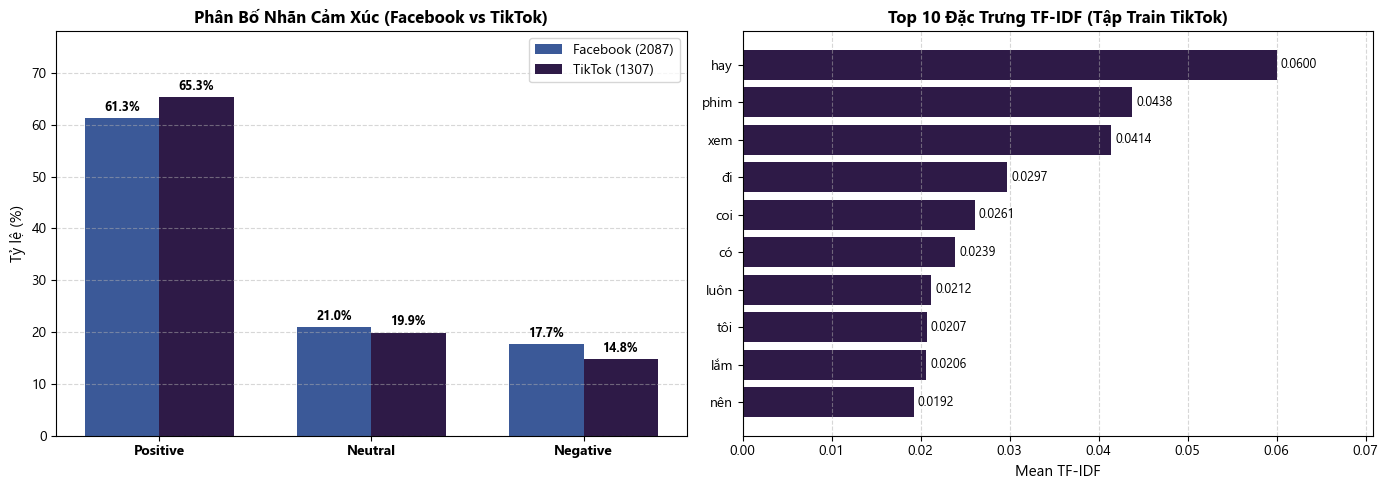

In [ ]:
# 7. TRỰC QUAN HÓA BIỂU ĐỒ SO SÁNH
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: So sánh phân bố nhãn
labels_list = ['Positive', 'Neutral', 'Negative']
x = np.arange(len(labels_list))
w = 0.35
tt_pcts = [sum(tt_labels == l)/len(tt_labels)*100 for l in labels_list]
fb_pcts = [sum(fb_labels == l)/len(fb_labels)*100 for l in labels_list]

b1 = ax1.bar(x - w/2, fb_pcts, w, label=f'Facebook ({len(df_fb)})', color='#3b5998')
b2 = ax1.bar(x + w/2, tt_pcts, w, label=f'TikTok ({len(df_tt)})', color='#2E1A47')


ax1.bar_label(b1, fmt='%.1f%%', padding=3, fontsize=9, fontweight='bold')
ax1.bar_label(b2, fmt='%.1f%%', padding=3, fontsize=9, fontweight='bold')
ax1.set_ylim(0, 78)
ax1.set_ylabel('Tỷ lệ (%)', fontsize=11)
ax1.set_title('Phân Bố Nhãn Cảm Xúc (Facebook vs TikTok)', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(labels_list, fontsize=10, fontweight='bold')
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Biểu đồ 2: Top 10 đặc trưng TF-IDF TikTok
top10_tt_idx = tt_scores.argsort()[::-1][:10]
words_tt = [vocab_tt_tfidf[i] for i in top10_tt_idx][::-1]
scores_tt = tt_scores[top10_tt_idx][::-1]
b_h = ax2.barh(words_tt, scores_tt, color='#2E1A47')  # Màu tím đen
ax2.bar_label(b_h, fmt='%.4f', padding=3, fontsize=9)
ax2.set_xlim(0, max(scores_tt) * 1.18)
ax2.set_title('Top 10 Đặc Trưng TF-IDF (Tập Train TikTok)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Mean TF-IDF', fontsize=11)
ax2.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Bước 7: Đóng gói và lưu trữ ma trận bàn giao
- Lưu trữ dưới định dạng `.joblib` tại `Data/vectorized/`.

In [8]:
# 8. ĐÓNG GÓI MA TRẬN & LƯU FILE BÀN GIAO
out_dir = os.path.join(DATA_DIR, 'vectorized')
os.makedirs(out_dir, exist_ok=True)

# Gói TikTok TF-IDF & BoW
joblib.dump({
    'X_train': X_train_tt_tfidf, 'y_train': tt_train_y, 'train_texts': tt_train_x, 'train_ids': tt_train_id,
    'X_test': X_test_tt_tfidf, 'y_test': tt_test_y, 'test_texts': tt_test_x, 'test_ids': tt_test_id,
    'vectorizer': tfidf_tt, 'feature_names': vocab_tt_tfidf.tolist()
}, os.path.join(out_dir, 'tiktok_tfidf_train_test.joblib'))

joblib.dump({
    'X_train': X_train_tt_bow, 'y_train': tt_train_y, 'train_texts': tt_train_x, 'train_ids': tt_train_id,
    'X_test': X_test_tt_bow, 'y_test': tt_test_y, 'test_texts': tt_test_x, 'test_ids': tt_test_id,
    'vectorizer': bow_tt, 'feature_names': vocab_tt_bow.tolist()
}, os.path.join(out_dir, 'tiktok_bow_train_test.joblib'))

# Gói Facebook TF-IDF & BoW
joblib.dump({
    'X_train': X_train_fb_tfidf, 'y_train': fb_train_y, 'train_texts': fb_train_x, 'train_ids': fb_train_id,
    'X_test': X_test_fb_tfidf, 'y_test': fb_test_y, 'test_texts': fb_test_x, 'test_ids': fb_test_id,
    'vectorizer': tfidf_fb, 'feature_names': vocab_fb_tfidf.tolist()
}, os.path.join(out_dir, 'facebook_tfidf_train_test.joblib'))

joblib.dump({
    'X_train': X_train_fb_bow, 'y_train': fb_train_y, 'train_texts': fb_train_x, 'train_ids': fb_train_id,
    'X_test': X_test_fb_bow, 'y_test': fb_test_y, 'test_texts': fb_test_x, 'test_ids': fb_test_id,
    'vectorizer': bow_fb, 'feature_names': vocab_fb_bow.tolist()
}, os.path.join(out_dir, 'facebook_bow_train_test.joblib'))

print(f'Đã lưu thành công toàn bộ ma trận tại: {os.path.abspath(out_dir)}')

Đã lưu thành công toàn bộ ma trận tại: C:\Nam 4 ki 1\Phan tich va khai pha du lieu van ban\BTL\Bai_1\Data\vectorized
